# Exposición Grupo 7 
# T-SNE y UMAP
## Reducción de dimensionalidad no lineal · Aplicación: Airbnb Barcelona

**Juan Esteban Castillo Romero · Laura Natalia Garcia Camargo · Daniel Mauricio Sanchez Duran · Mateo Ramirez Cabrera**

---
# 1. Objetivo y motivación

PCA y MCA sirven para tomar datos con muchísimas variables y llevarlos a dos
dimensiones, para poder visualizarlos. Pero son **lineales**.

**t-SNE y UMAP hacen lo mismo, pero no son lineales** — y eso les permite
encontrar estructuras que los lineales no ven.

**Objetivo:** construir un mapa en 2D que conserve las **vecindades**
(lo que estaba cerca en muchas dimensiones sigue cerca en el dibujo).
PCA conserva la varianza; t-SNE y UMAP conservan la vecindad.



---
# 2. ¿Por qué PCA no basta?

## **¿Por qué PCA no funciona?**



Recordemos brevemente lo que hace PCA, esta técnica de reducción consiste en:

*   Calcular matriz de covarianzas a partir de los datos, donde la diagonal es la varianza que tiene cada variable, y todo fuera de la diagonal es la covarianza que hay entre pares de variables.
*   Calcular vectores propios para determinar las direcciones de máxima varianza de los datos.
*   Calcular valores propios para determinar cuánta varianza hay en cada una de esas direcciones.
*   Proyectar los datos sobre los primeros vectores, lo que los "aplasta" en un plano que hace que pierda la menor cantidad de varianza explicativa posible.





***Donde PCA si tiene éxito***

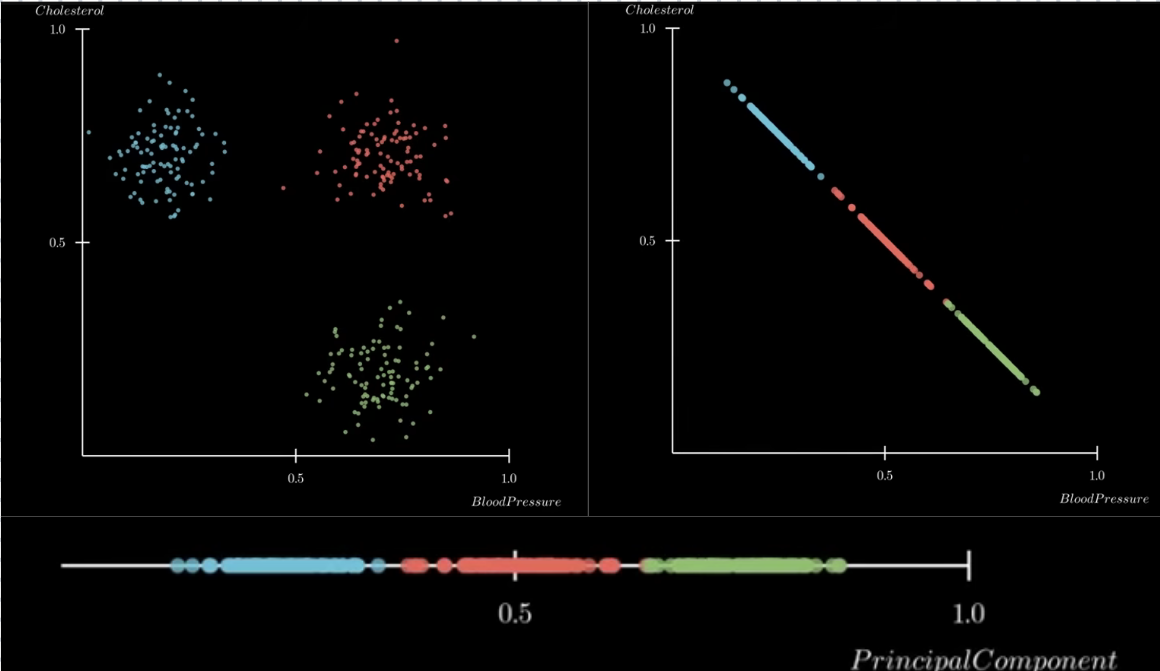

## ***Swiss Roll***

El problema, o la limitación de PCA que hace que no sea suficiente para otros casos es que, al ser una técnica úitl para datos en variedades lineales, que se apoya sobre una proyección lineal, que es, por definición, cortar el espacio con líneas o planos, en un supuesto caso donde la estructura real de los datos es curva, no existe ningún plano, por bien escogido que esté, que la represente sin distorsión.
Aquí, para ilustrar mejor esta idea y explicar esta limitación de PCA, traemos el caso ***Swiss Roll***

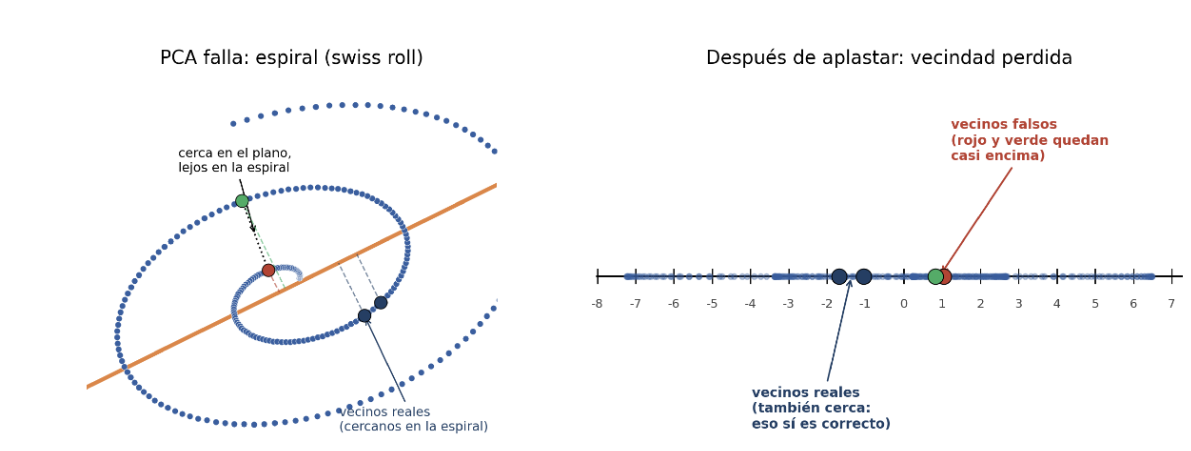

En un supuesto donde nuestros datos tiene una distribución en el espacio de forma curva o similar a una galaxia, ejecutar el mismo procedimiento líneal que se lleva a cabo a través de PCA resulta erroneo, aquí surge el concepto de "falsos vecinos", en el sentido de que, si aplastamos estos puntos en una recta, algunos puntos serán señalados como vecinos, es decir, que comparten características, sin embargo, si nos devolvemos a su distribución original, nos daremos cuenta que no estaban cerca y que pertenecían a diferentes niveles de la curvatura, dejándonos así presencia de vecinos falsos que distorcionan las verdaderas propiedades de mis datos en términos de grupos o clusters.


Cualquier estructura curva en los datos reales corre el mismo riesgo si la aplastamos con una operación lineal. Y para esta caso, PCA **rompió la estructura** real de los datos.

## ***lo que PCA no supo ver y por eso no es suficiente***

Pero entonces, ¿cuál era la estructura real que sí tenían esos datos?

Aquí, y al rededor de este diagrama, surge un concepto que nos explica algo adicional a la limitación de PCA, siendo este ***manifolds***. Formalmente, se habla de una variedad de dimensión d que está inmersa en un espacio de dimensión superior D (D > d), cuando vemos localmente cada trozo de esta estructura, este se parece a un espacio plano de dimensión d, aunque globalmente esté doblado o curvado dentro del espacio D que es más grande.

Un habitante diminuto caminando sobre el papel solo percibiría dos direcciones de movimiento posibles, aunque desde afuera veamos que ese papel ocupa tres coordenadas.


El swiss roll es plano en su naturaleza, porque solo necesitamos 2 coordenadas para describir cualquier punto sobre el papel. Al enrollarlo, ese papel de 2 dimensiones queda "escondido" dentro de un espacio de 3 dimensiones. Esa superficie plana escondida es lo que llamamos un manifold.

Si logramos "desenrollar" los datos respetando su superficie real, en lugar de aplastarlos con una línea recta, recuperamos la estructura que PCA no pudo ver.

Es un poco como intentar poner sobre una mesa plana todas las relaciones de distancia que existen entre las ciudades de una esfera terrestre: por más que uno se esfuerce, no hay forma de aplastar esa estructura sin que algunas distancias se compriman.

## ***Crowding Problem y la puerta hacia lo que sigue***

La idea central en torno a este problema es que cuando se intenta representar en un espacio de 2 dimensiones relaciones de vecindad que existían en un espacio de muchas dimensiones, sencillamente no hay suficiente "espacio" para acomodar a todos los puntos que en el espacio original estaban moderadamente cerca entre si. En dimensiones altas cabe mucha más gente alrededor de un punto que en un plano 2D, así que al aplastar todo en dos dimensiones, muchos puntos que solo eran vecinos moderados, es decir, que ni muy cerca ni muy lejos entre ellos, se ven forzados a apretujarse cerca del centro del mapa, mezclando grupos que en realidad estaban separados.

Este es uno de los problemas que intenta resolver el método t-SNE, cuyo desarrollo viene a continuación.

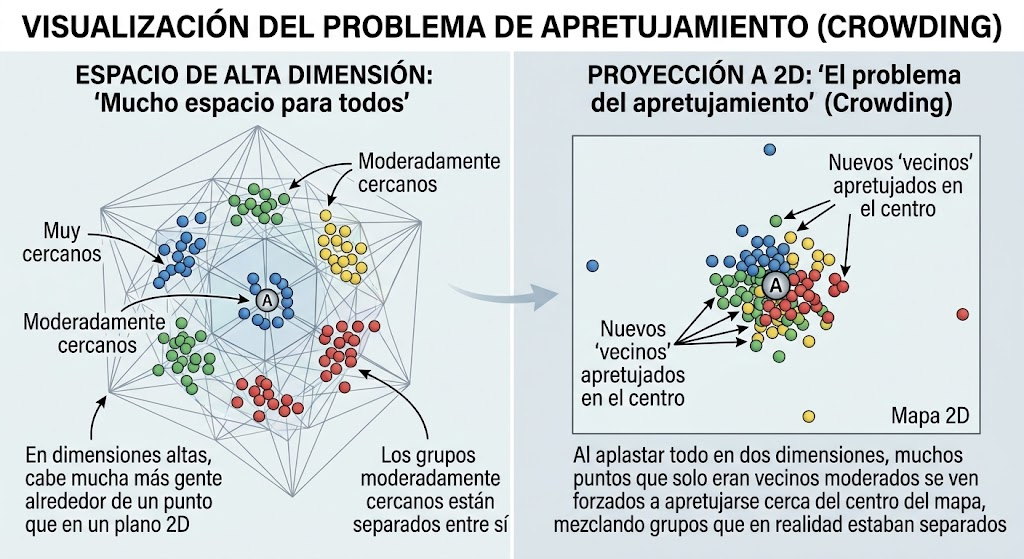

---
# 3. Demo: el mamut y la maldición de la dimensionalidad

Dos demostraciones que cierran lo que explicó Juan Esteban:
1. **El mamut**: una figura cuya forma conocemos, para ver qué le hace cada método al aplastarla en 2D.
2. **La tabla de distancias**: la maldición de la dimensionalidad, en números.

## 3.0 Librerías

| Librería | Para qué la usamos |
|---|---|
| `json`, `os`, `urllib.request` | Vienen con Python. Descargar el archivo del mamut, guardarlo en disco y volver a leerlo |
| `numpy` | Trabajar con matrices de números: muestreo aleatorio y cálculo de distancias |
| `pandas` | Manejar la tabla de Airbnb (se usa en la sección 4) |
| `matplotlib` | Los gráficos estáticos en 2D |
| `plotly` | El gráfico 3D interactivo que se puede girar con el mouse |
| `sklearn.decomposition.PCA` | La reducción lineal, en el módulo `decomposition` |
| `sklearn.manifold.TSNE` | La reducción no lineal, en el módulo `manifold` (variedades) |

In [36]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from sklearn.decomposition import PCA     # reducción lineal
from sklearn.manifold import TSNE         # reducción no lineal

plt.rcParams["figure.dpi"] = 110          # figuras más nítidas al proyectar
print("Listo")

Listo


## 3.1 Descargar los datos del mamut

Esqueleto de mamut lanudo escaneado en 3D por el Smithsonian, publicado por Google PAIR en *Understanding UMAP*


In [37]:
ARCHIVO = "mammoth.json"
URL = ("https://raw.githubusercontent.com/PAIR-code/understanding-umap/"
       "master/raw_data/mammoth_umap.json")

if os.path.exists(ARCHIVO):
    with open(ARCHIVO) as f:
        mamut = json.load(f)
    print("Cargado desde el archivo local (no necesitó internet)")
else:
    with urllib.request.urlopen(URL) as r:
        mamut = json.loads(r.read())
    with open(ARCHIVO, "w") as f:
        json.dump(mamut, f)
    print(f"Descargado de GitHub y guardado como {ARCHIVO}")

X_mam = np.array(mamut["3d"])      # matriz 10000 x 3: los puntos del esqueleto
y_mam = np.array(mamut["labels"])  # 10000 etiquetas: parte del cuerpo de cada punto

print(f"\n{X_mam.shape[0]} puntos × {X_mam.shape[1]} dimensiones")
print(f"{len(set(y_mam))} partes del cuerpo distintas")

Cargado desde el archivo local (no necesitó internet)

10000 puntos × 3 dimensiones
11 partes del cuerpo distintas


## 3.2 El mamut en 3D


In [38]:
fig = go.Figure(data=[go.Scatter3d(
    x=X_mam[:, 0], y=X_mam[:, 1], z=X_mam[:, 2],
    mode="markers",
    marker=dict(size=1.2, color=y_mam, colorscale="Turbo", showscale=False),
)])
fig.update_layout(
    width=800, height=600, margin=dict(l=0, r=0, t=40, b=0),
    title="Mamut lanudo en 3D",
    scene=dict(xaxis=dict(visible=False), yaxis=dict(visible=False),
               zaxis=dict(visible=False), aspectmode="data"),
)
fig.show()

## 3.3 Qué le hace PCA

`PCA(n_components=2)` crea el reductor y `.fit_transform()` hace dos cosas: aprende las dos direcciones de máxima varianza (los vectores propios de la matriz de covarianza) y proyecta los 10.000 puntos sobre ellas. Entra una matriz de 10.000 × 3 y sale una de 10.000 × 2.



/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


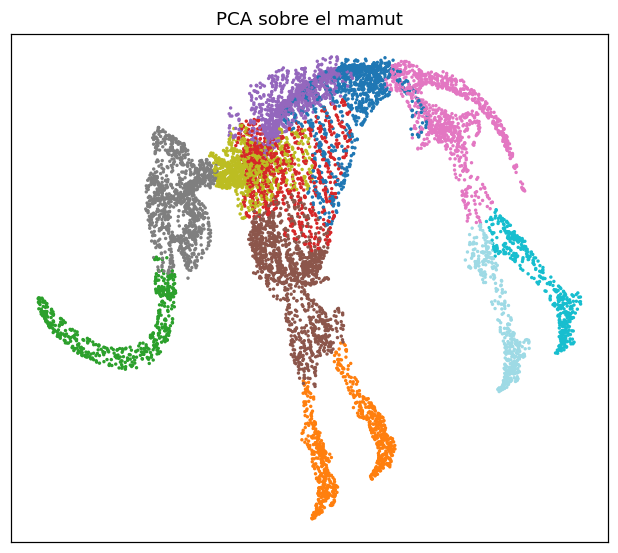

In [39]:
Z_pca_mam = PCA(n_components=2).fit_transform(X_mam)

plt.figure(figsize=(7, 6))
plt.scatter(Z_pca_mam[:, 0], Z_pca_mam[:, 1], c=y_mam, cmap="tab20", s=1.5)
plt.title("PCA sobre el mamut")
plt.xticks([]); plt.yticks([])
plt.show()

## 3.4 Adelanto: qué le hace t-SNE

 Mismos datos, mismo objetivo de llevarlos a 2D, criterio completamente distinto.


/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWa

t-SNE tardó 11 segundos con 10000 puntos


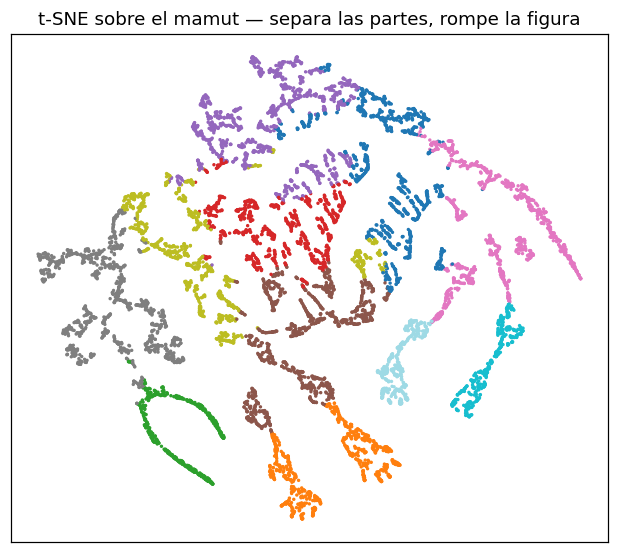

In [40]:
import time

t0 = time.time()
Z_tsne_mam = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_mam)
print(f"t-SNE tardó {time.time()-t0:.0f} segundos con {len(X_mam)} puntos")

plt.figure(figsize=(7, 6))
plt.scatter(Z_tsne_mam[:, 0], Z_tsne_mam[:, 1], c=y_mam, cmap="tab20", s=1.5)
plt.title("t-SNE sobre el mamut — separa las partes, rompe la figura")
plt.xticks([]); plt.yticks([])
plt.show()

Todas las partes del cuerpo separadas y mejor delimitadas pero se perdio la figura del mammut

## 3.5 La maldición de la dimensionalidad, en números

Para cada dimensión: generamos 500 puntos al azar, medimos la distancia entre **todas** las parejas y miramos la más corta, la más larga y la razón entre ambas.

- `rng.random((500, d))` → 500 puntos en dimensión d, con coordenadas entre 0 y 1.
- `P[:, None, :] - P[None, :, :]` → resta todos los puntos contra todos (broadcasting de numpy).
- `np.linalg.norm(..., axis=2)` → convierte esas diferencias en distancias euclidianas.
- `np.triu_indices(len(P), k=1)` → toma solo el triángulo superior, para no contar dos veces cada pareja ni incluir la distancia de un punto consigo mismo.

In [41]:
rng = np.random.default_rng(0)

print(f"{'dimensión':>10} {'dist. mínima':>14} {'dist. máxima':>14} {'razón máx/mín':>15}")
print("-" * 56)

for d in [2, 5, 20, 100, 500]:
    P = rng.random((500, d))
    D = np.linalg.norm(P[:, None, :] - P[None, :, :], axis=2)
    D = D[np.triu_indices(len(P), k=1)]
    print(f"{d:>10} {D.min():>14.2f} {D.max():>14.2f} {D.max()/D.min():>15.1f}")

 dimensión   dist. mínima   dist. máxima   razón máx/mín
--------------------------------------------------------
         2           0.00           1.36           656.8
         5           0.08           1.85            24.4
        20           0.77           2.96             3.8
       100           3.04           5.04             1.7
       500           7.96          10.15             1.3


Para T-SNE Y UMAP no usamos distancias en bruto sino que las convertimos en vecindades relativas
T-SNE en probabilidades
UMAP en grafos

---
# 4. Los datos

 **t-SNE y UMAP miden parecido calculando distancias**. De ahí salen las dos exigencias que vamos a resolver aquí: solo pueden entrar variables cuantitativas, y todas deben estar en una escala comparable.

## 4.1 La base

In [42]:
df = pd.read_csv("listings.csv.gz", low_memory=False)

print(f"{df.shape[0]} anuncios × {df.shape[1]} columnas")

18927 anuncios × 79 columnas


## 4.2 Qué columnas entran y cuáles no

Las 79 columnas se reparten en tres grupos:

| Grupo | Qué contiene | Qué hacemos |
|---|---|---|
| **Se descartan (61)** | Texto libre, URLs, fotos, `id`, `host_id` | No son cantidades: no se pueden restar |
| **Entran (16)** | Cuantitativas del anuncio: precio, camas, capacidad, calificaciones | Forman el espacio de alta dimensión |
| **Etiquetas (2)** | Tipo de alojamiento, distrito | NO entran al algoritmo; solo para colorear |

**Sobre los identificadores:** son números, pero no son cantidades. Que un anuncio tenga id 5000 y otro 5001 no significa que se parezcan.

**Sobre las categóricas:** t-SNE y UMAP necesitan distancias, así que trabajan con cuantitativas, igual que PCA y a diferencia de MCA, que es el método para categóricas.

**Por qué las etiquetas no entran — el punto clave:** el color se pone *después*, encima del resultado ya calculado. Si le diéramos el tipo de alojamiento como variable y luego los grupos salieran separados por tipo, no probaríamos nada: sería como preguntarle a alguien la respuesta y después felicitarlo por acertar.

In [43]:
# Las 16 variables cuantitativas que SÍ entran al algoritmo
COLS = [
    "accommodates",                          # cuántas personas caben
    "bathrooms", "bedrooms", "beds",         # tamaño del alojamiento
    "price",                                 # precio por noche
    "minimum_nights",                        # estadía mínima
    "availability_30", "availability_365",   # días disponibles
    "number_of_reviews", "reviews_per_month",  # actividad
    "review_scores_rating",                  # calificación general
    "review_scores_cleanliness",             # limpieza
    "review_scores_location",                # ubicación
    "review_scores_value",                   # relación calidad-precio
    "calculated_host_listings_count",        # anuncios del anfitrión
    "estimated_occupancy_l365d",             # ocupación estimada del último año
]

# Las 2 categóricas que NO entran: solo sirven para colorear
ETIQUETAS = ["room_type", "neighbourhood_group_cleansed"]

print(f"{len(COLS)} entran | {len(ETIQUETAS)} etiquetas | "
      f"{df.shape[1]-len(COLS)-len(ETIQUETAS)} se descartan")

16 entran | 2 etiquetas | 61 se descartan


### Las categorías de cada etiqueta

Conviene verlas antes, para saber qué esperar en los gráficos.

In [44]:
for col in ETIQUETAS:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- room_type ---
room_type
Entire home/apt    11657
Private room        7087
Shared room           92
Hotel room            91
Name: count, dtype: int64

--- neighbourhood_group_cleansed ---
neighbourhood_group_cleansed
Eixample               6655
Ciutat Vella           4344
Sants-Montjuïc         1913
Sant Martí             1766
Gràcia                 1626
Sarrià-Sant Gervasi    1144
Horta-Guinardó          565
Les Corts               393
Sant Andreu             310
Nou Barris              211
Name: count, dtype: int64



El tipo de alojamiento tiene cuatro categorías, pesan dos que son casa entera y habitación privada. 

El distrito tiene diez, muy desbalanceadas, concentradas en Eixample y Ciutat Vella que son centro turistico

## 4.3 Limpieza

Tres arreglos:

1. **El precio viene como texto** (`$80.00`, con símbolo y coma de miles) → se convierte a número.
2. **Faltan datos**: los anuncios sin reseñas no tienen calificación, y no se puede calcular la distancia a un punto con coordenadas vacías. Se eliminan esas filas en vez de rellenarlas, porque inventar calificaciones podría crear grupos falsos.
3. **Hay precios extremos**: anuncios de 10.000 euros la noche contra una mediana de 143.

In [45]:
# 1. Precio de texto a número: quitamos "$" y "," con una expresión regular
print("Precio antes: ", df["price"].dropna().head(3).tolist())
df["price"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)
print("Precio después:", df["price"].dropna().head(3).tolist())

# 2. Nos quedamos con las columnas que nos interesan y eliminamos filas incompletas
datos = df[COLS + ETIQUETAS].dropna()

# 3. Quitamos precios extremos (y los de 0, que serían errores de registro)
antes = len(datos)
datos = datos[(datos["price"] > 0) & (datos["price"] < 1000)]

print(f"\n{len(df)} anuncios → {len(datos)} anuncios limpios")

Precio antes:  ['$232.00', '$382.00', '$186.00']
Precio después: [232.0, 382.0, 186.0]

18927 anuncios → 11248 anuncios limpios


## 4.4 La muestra

t-SNE calcula la distancia de cada punto con todos los demás, así que su costo crece con el **cuadrado** del número de puntos: el doble de anuncios son cuatro veces más parejas.

In [46]:
muestra = datos.sample(5000, random_state=42)

# Etiquetas guardadas aparte, en el MISMO orden que las filas de la muestra:
# el punto i del gráfico corresponde a la etiqueta i de estas listas.
tipo = muestra["room_type"].values
barrio = muestra["neighbourhood_group_cleansed"].values

m = len(muestra)
print(f"Muestra: {m} anuncios")
print(f"Parejas que compara t-SNE: {m*(m-1)//2:,}")
print(f"Con el doble de anuncios ({2*m}) serían: {(2*m)*(2*m-1)//2:,} → 4 veces más")

Muestra: 5000 anuncios
Parejas que compara t-SNE: 12,497,500
Con el doble de anuncios (10000) serían: 49,995,000 → 4 veces más


## 4.5 El escalado

La distancia entre dos anuncios suma las diferencias de todas las variables:

$$d(a,b) = \sqrt{\sum_{k=1}^{16}(a_k - b_k)^2}$$

**Un ejemplo concreto.** Dos anuncios: uno de 100 € con 2 camas y calificación 4.9, y otro de 300 € con 6 camas y calificación 4.0.

| Variable | Diferencia | Al cuadrado |
|---|---|---|
| Precio | 200 | **40.000** |
| Camas | 4 | 16 |
| Calificación | 0.9 | 0.81 |

El precio aporta el **99,96%** de la distancia. El algoritmo estaría agrupando por precio y nada más, y eso pasa solo por las unidades: el precio se mide en cientos y las camas en unidades.

**La solución, en dos pasos:**

1. **Logaritmo** (`np.log1p`, que calcula log(1+x) y por eso admite ceros) sobre las variables sesgadas: comprime la cola larga, de modo que pasar de 50 a 100 euros pese parecido a pasar de 500 a 1000.
2. **Estandarización** ($z = (x-\mu)/\sigma$): deja cada variable con media 0 y desviación 1, o sea que la diferencia se mide *en unidades de lo que esa variable suele variar*. Las 16 pasan a pesar lo mismo.

In [47]:
print("Rango de cada variable ANTES de escalar:")
print(muestra[COLS].agg(["min", "max"]).T)

Rango de cada variable ANTES de escalar:
                                  min      max
accommodates                     1.00    16.00
bathrooms                        0.00     8.00
bedrooms                         0.00     8.00
beds                             0.00    18.00
price                           10.00   996.00
minimum_nights                   1.00   865.00
availability_30                  0.00    30.00
availability_365                 0.00   365.00
number_of_reviews                1.00  1323.00
reviews_per_month                0.01    26.09
review_scores_rating             1.00     5.00
review_scores_cleanliness        1.00     5.00
review_scores_location           1.00     5.00
review_scores_value              1.00     5.00
calculated_host_listings_count   1.00   522.00
estimated_occupancy_l365d        0.00   255.00


In [48]:
from sklearn.preprocessing import StandardScaler

# .fit() aprende la media y la desviación de cada columna; .transform() las aplica.
# Guardamos el escalador porque se reutiliza en la sección de UMAP.
escalador = StandardScaler().fit(np.log1p(muestra[COLS].clip(lower=0)))
X = escalador.transform(np.log1p(muestra[COLS].clip(lower=0)))

print(f"DESPUÉS de escalar → media ≈ {X.mean():.2f}, desviación ≈ {X.std():.2f}")
print(f"\nMatriz final: {X.shape[0]} anuncios × {X.shape[1]} variables")

DESPUÉS de escalar → media ≈ 0.00, desviación ≈ 1.00

Matriz final: 5000 anuncios × 16 variables


## 4.6 La demostración: qué pasa si NO se escala

Corremos t-SNE dos veces sobre los mismos anuncios: una con los datos crudos y otra con los datos escalados. Mismo algoritmo, mismos parámetros, misma semilla.

/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWa

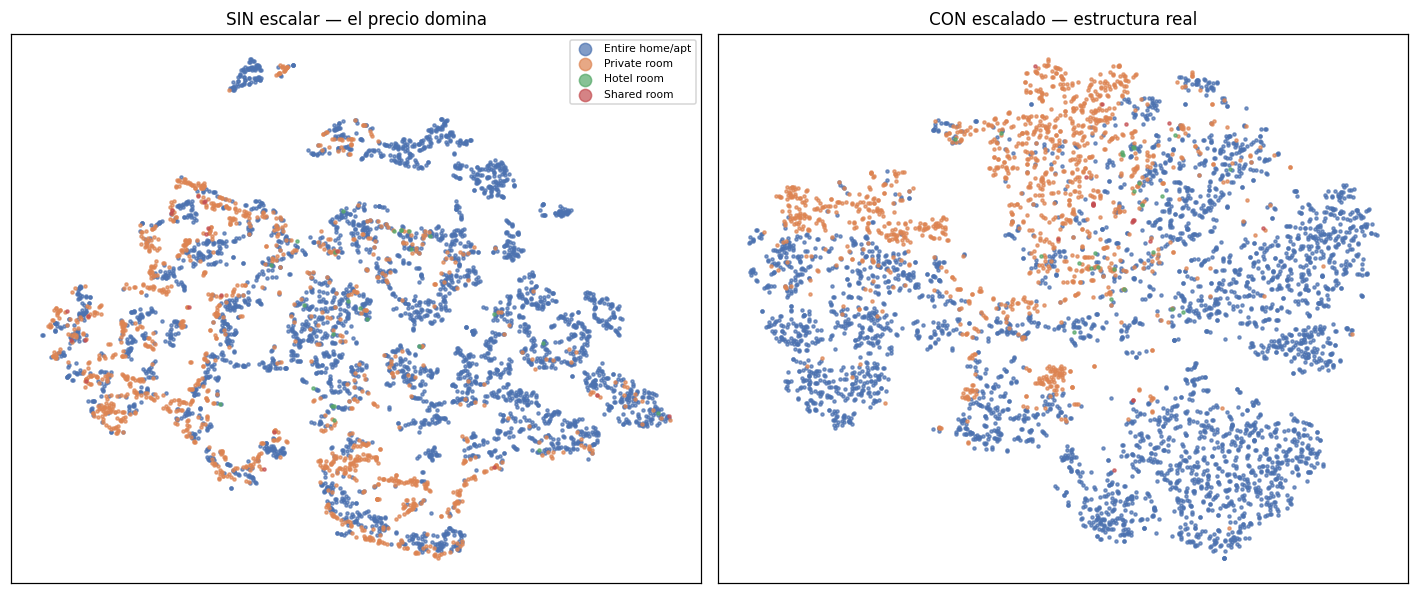

In [49]:
COLORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3",
           "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD"]

def graficar(Z, etiquetas, titulo, ax=None, leyenda=True, s=4):
    """Dibuja un embedding 2D coloreado por etiqueta. Se usa en todo el notebook
    para que los colores sean siempre los mismos y la comparación sea justa."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 5.5))
    for i, clase in enumerate(pd.Series(etiquetas).value_counts().index):
        mask = np.asarray(etiquetas) == clase
        ax.scatter(Z[mask, 0], Z[mask, 1], s=s, alpha=0.7,
                   color=COLORES[i % len(COLORES)], label=str(clase))
    ax.set_title(titulo, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    if leyenda:
        ax.legend(markerscale=4, fontsize=7, loc="best")
    return ax

X_sin_escalar = muestra[COLS].values   # los valores tal como vienen


## t-SNE: sin escalar vs. con escalado
Z_mal = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_sin_escalar)
Z_bien = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
graficar(Z_mal, tipo, "SIN escalar — el precio domina", axes[0])
graficar(Z_bien, tipo, "CON escalado — estructura real", axes[1], leyenda=False)
plt.tight_layout(); plt.show()

a la izquierda está t-SNE con los datos crudos, donde los tipos de alojamiento salen entreverados porque el algoritmo prácticamente ordenó por precio; y a la derecha, con escalado, aparece la estructura real. Mismos anuncios, mismo algoritmo, mismos parámetros: lo único que cambió fue el escalado.*

 *Nos queda una matriz de cinco mil anuncios por dieciséis variables, y sobre esta misma van a trabajar los dos algoritmos."*

**Variables disponibles para el resto del notebook:** `X` (la matriz), `tipo` y `barrio` (las etiquetas), `muestra` (la tabla original de esos 5.000 anuncios), `escalador` (se reutiliza en UMAP) y la función `graficar()`.

---
# 5. Teoría de t-SNE

## **t-SNE: t-distributed Stochastic Neighbor Embedding**

Ya vimos cómo PCA, al ser una proyección lineal, rompe la estructura del manifold y sufre del problema de apiñamiento (*Crowding Problem*). Aquí es donde entra **t-SNE**, desarrollado en 2008 por Laurens van der Maaten y Geoffrey Hinton.

A diferencia de PCA, t-SNE es una técnica de **reducción de dimensionalidad no lineal**. Sacrifica deliberadamente la estructura global (la varianza total) para preservar estrictamente la **estructura local** (las vecindades entre los puntos). Para lograrlo, t-SNE abandona las distancias euclidianas puras y da el salto al mundo de las probabilidades.

### 1. De distancias a probabilidades (El espacio original)

> 💡 **Analogía intuitiva:** Imagina que estás en una fiesta. Las personas con las que hablas más fuerte son tus amigos más cercanos, y tu voz se desvanece para los que están lejos. Sin embargo, si estás en una sala muy ruidosa y abarrotada, tienes que gritar muy fuerte pero tu voz llega a muy poca distancia. Si estás en el jardín exterior donde hay pocas personas, puedes hablar a un volumen normal y ser escuchado mucho más lejos. Ese "rango de tu voz" es la varianza $\sigma$.

En el espacio original de alta dimensión, t-SNE centra una campana de Gauss sobre cada punto $x_i$. La distancia hacia otro punto $x_j$ se convierte en la probabilidad condicional de que $x_i$ elija a $x_j$ como su vecino.

El algoritmo asigna una desviación estándar ($\sigma_i$) distinta para cada punto basándose en la densidad local: un $\sigma_i$ pequeño en zonas densas y uno grande en zonas dispersas. Esto permite que el algoritmo sea igual de sensible a clústeres compactos que a clústeres difusos.

$$p_{j|i}=\frac{\exp(-||x_i-x_j||^2/2\sigma_i^2)}{\sum_{k\neq i}\exp(-||x_i-x_k||^2/2\sigma_i^2)}$$

Para facilitar la optimización matemática, se simetrizan estas probabilidades ($p_{ij}=p_{ji}$) dividiendo entre el número total de puntos $n$:

$$p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}$$

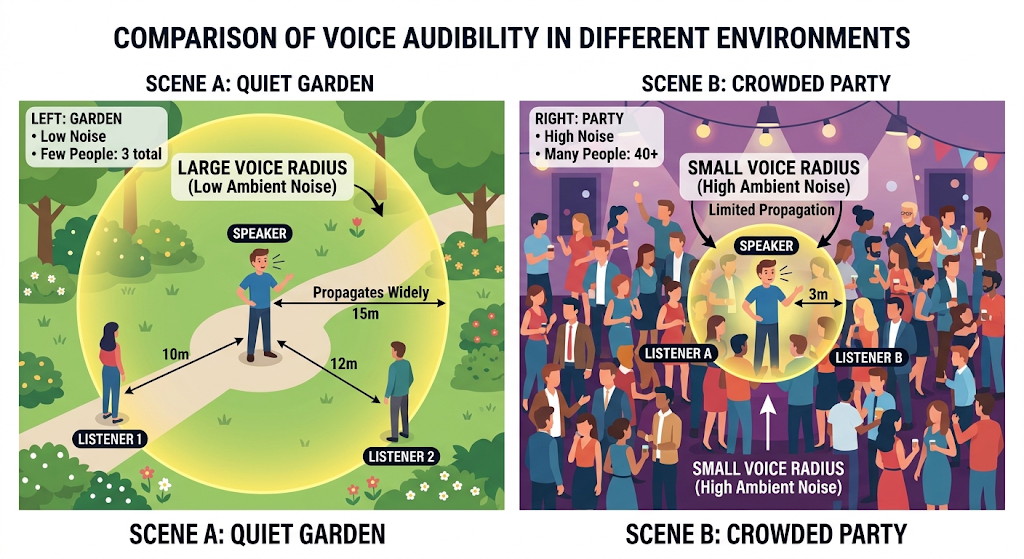

### 2. Calibrando las relaciones: La Perplexity

> 💡 **Analogía intuitiva:** Piensa en la perplejidad como el número de "invitados VIP" a los que cada punto va a prestar atención real en la fiesta. Si la ajustas a 5, el punto solo intentará mantener cerca a sus 5 amigos íntimos, ignorando al resto. Si la ajustas a 500 en una fiesta de 1000 personas, el punto intentará relacionarse con la mitad del salón, perdiendo su estructura íntima.

La perplejidad ($Perp$) es el hiperparámetro fundamental que controla el usuario. Se deriva de la entropía de Shannon ($H$) y le indica al algoritmo mediante una búsqueda binaria cómo de ancho debe ser el $\sigma_i$ para cada punto.

$$Perp=2^{H(P_i)}$$
$$H(P_i)=-\sum_{j}p_{j|i}\log_2 p_{j|i}$$

*   **Valores bajos (ej. 2-5):** Generan sobreajuste al ruido local, creando micro-grupos sin sentido.
*   **Valores altos:** El algoritmo colapsa y pierde la estructura local, intentando emular el comportamiento global de PCA.

### 3. El espacio reducido y la distribución t de Student

> 💡 **Analogía intuitiva:** En 50 dimensiones hay mucho "espacio libre". Cuando intentas forzar a todos esos puntos a vivir en un apartamento de 2 dimensiones, se aplastan unos contra otros (*Crowding Problem*). La distribución t de Student actúa como un resorte magnético: permite que los puntos cercanos sigan juntos, pero empuja artificialmente a los puntos lejanos hacia las afueras para que los clústeres respiren.

Mientras que en el espacio original se usa una Gaussiana, en el mapa de 2D se utiliza una distribución t de Student. Debido a que esta distribución tiene "colas pesadas" (la campana no cae tan rápido a cero), para representar una distancia moderada del espacio original, en el mapa 2D el punto tiene que ser colocado geométricamente mucho más lejos.

$$q_{ij}=\frac{(1+||y_i-y_j||^2)^{-1}}{\sum_{k\neq l}(1+||y_k-y_l||^2)^{-1}}$$




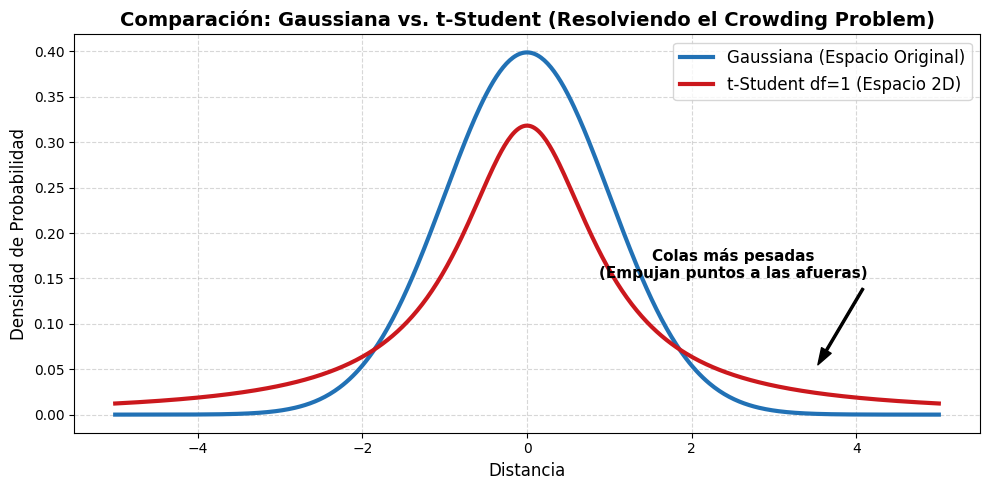

### 4. La Divergencia de Kullback-Leibler y la Optimización

> 💡 **Analogía intuitiva:** Tienes un mapa oficial topográfico ($p_{ij}$) y un bosquejo dibujado a mano ($q_{ij}$). La Divergencia KL es la multa que debes pagar por cada error. Si en el mapa oficial dos ciudades están juntas, pero en tu bosquejo las dibujaste separadas, la multa es gigantesca. Pero si en el mapa oficial están separadas y tú las acercaste, la multa es muy pequeña.

El objetivo de t-SNE es minimizar la diferencia entre la distribución original $P$ y la distribución en baja dimensión $Q$ usando la Divergencia KL mediante Descenso de Gradiente. Es asimétrica, por lo que penaliza fuertemente separar puntos que debían estar juntos.

$$C=KL(P||Q)=\sum_{i\neq j}p_{ij}\log\frac{p_{ij}}{q_{ij}}$$

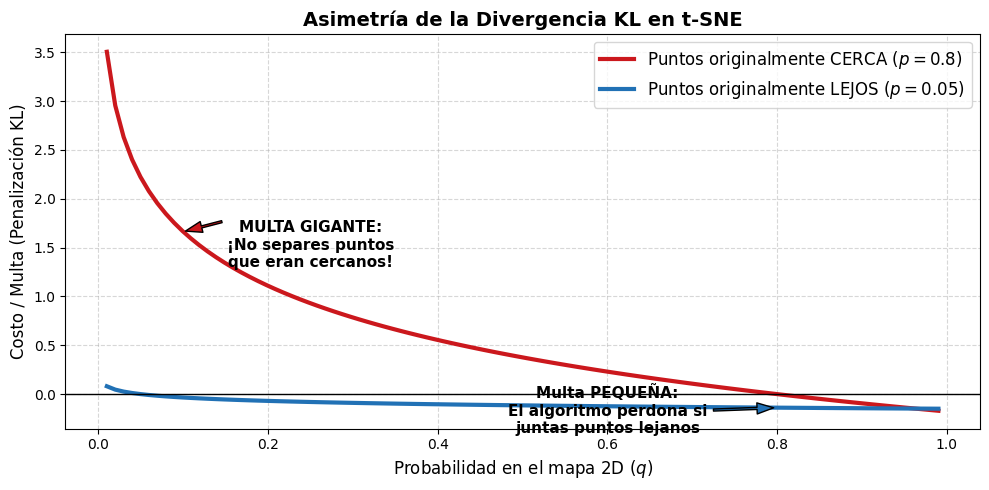


### Limitaciones y Errores Comunes de Interpretación

1.  **La distancia y el tamaño no significan nada:** Como el algoritmo adapta la varianza a la densidad, un clúster originalmente disperso se encogerá visualmente y uno denso se expandirá.
2.  **Es un método estocástico:** Arranca desde una inicialización aleatoria de los puntos, por lo que dos ejecuciones con la misma data generarán mapas distintos.
3.  **No es paramétrico:** A diferencia de PCA, t-SNE no crea una matriz por la que puedas multiplicar datos futuros. Si llega un nuevo registro, se debe recalcular todo desde cero.

**Errores a evitar en las gráficas:**
*    Interpretar el área visual de un clúster como la varianza original.
*    Creer que la cercanía entre dos clústeres distantes implica similitud global.
*    Aplicar algoritmos de distancias puras (como K-Means) sobre las coordenadas (x,y) generadas por t-SNE.

---
# 6. Demo: t-SNE sobre Airbnb

## 6.1 Qué es un "vecino", con datos reales

Antes de ver el resultado, veamos qué calcula el algoritmo por dentro. Tomamos un anuncio cualquiera y convertimos su distancia a los otros 4.999 en probabilidades de ser vecinos, con una campana de Gauss.

**El código, paso a paso:**
- `np.linalg.norm(X - X[i], axis=1)` → resta el anuncio *i* a todos los demás y calcula la distancia euclidiana de cada resta. Queda un vector con 5.000 distancias.
- `np.exp(-distancias**2 / (2*sigma**2))` → la fórmula de la campana de Gauss. Como el exponente es negativo, las distancias grandes dan valores diminutos y las pequeñas valores altos.
- `p[i] = 0` → un punto no es vecino de sí mismo.
- `p / p.sum()` → normaliza para que todas las probabilidades sumen 1.
- `np.argsort(-p)[:5]` → ordena de mayor a menor probabilidad y toma los cinco primeros.

In [50]:
i = 0                          # el anuncio que tomamos como referencia
sigma = 3.0                    # ancho de la campana (en t-SNE lo fija la perplexity)

distancias = np.linalg.norm(X - X[i], axis=1)   # distancia del anuncio i a todos
p = np.exp(-distancias**2 / (2 * sigma**2))     # distancias → afinidades (campana de Gauss)
p[i] = 0                                        # un punto no es vecino de sí mismo
p = p / p.sum()                                 # normalizamos: ahora suman 1

vecinos = np.argsort(-p)[:5]                    # los 5 de mayor probabilidad
mostrar = ["room_type", "accommodates", "price", "review_scores_rating"]

print("ANUNCIO DE REFERENCIA:")
print(muestra[mostrar].iloc[i].to_string())
print("\nSUS 5 VECINOS MÁS PROBABLES:")
print(muestra[mostrar].iloc[vecinos].to_string())
print(f"\nProbabilidad del vecino más cercano: {p[vecinos[0]]:.6f}")
print(f"Probabilidad de un anuncio lejano:   {np.sort(p)[5]:.2e}")

ANUNCIO DE REFERENCIA:
room_type               Entire home/apt
accommodates                          4
price                             257.0
review_scores_rating               4.92

SUS 5 VECINOS MÁS PROBABLES:
            room_type  accommodates  price  review_scores_rating
730   Entire home/apt             4  333.0                  4.88
1138  Entire home/apt             4  194.0                  4.84
3703  Entire home/apt             4  231.0                  4.90
776   Entire home/apt             4  171.0                  4.89
4645  Entire home/apt             3  248.0                  4.94

Probabilidad del vecino más cercano: 0.000502
Probabilidad de un anuncio lejano:   7.36e-16


## 6.2 El resultado sobre los 5.000 anuncios

Reutilizamos el resultado que ya calculamos en la sección 4 (`Z_bien`), para no repetir los 15 segundos de cómputo. Allá lo usamos como evidencia del escalado; acá lo miramos en grande para interpretarlo.

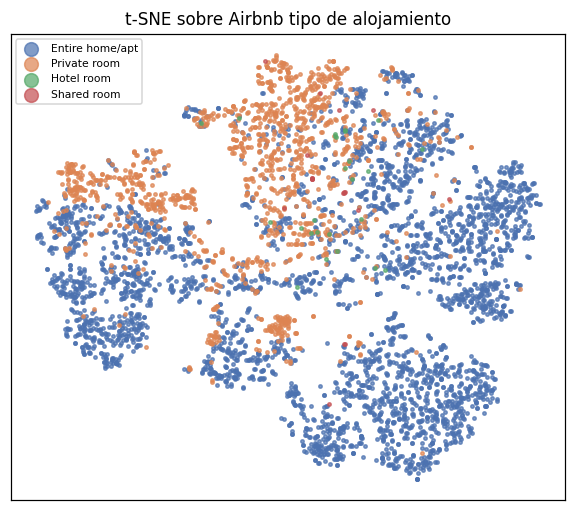

In [51]:
graficar(Z_bien, tipo, "t-SNE sobre Airbnb tipo de alojamiento", s=5)
plt.show()

Cada punto es un anuncio qeus e ubico basado en lo que T-SNE decidio a partir de las 16 variables

El color es el tipo de alojamiento. 

## 6.3 ¿Qué tan buena es esa separación?

A simple vista hay colores mezclados, así que conviene medirlo en vez de opinar. La métrica es sencilla: para cada anuncio miramos sus **10 vecinos más cercanos en el gráfico** y contamos qué proporción tiene su mismo tipo de alojamiento. A eso se le llama *pureza del vecindario*.

Comparamos tres cosas: el resultado sin escalar, el escalado, y qué saldría si los puntos estuvieran regados al azar (que es la suma de los cuadrados de las proporciones de cada categoría).

In [52]:
from sklearn.neighbors import NearestNeighbors

def pureza(Z, etiquetas, k=10):
    """Proporción promedio de los k vecinos más cercanos que comparten etiqueta."""
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Z)   # k+1 porque el primero es el punto mismo
    _, idx = nn.kneighbors(Z)
    return np.mean([np.mean(etiquetas[idx[j, 1:]] == etiquetas[j]) for j in range(len(Z))])

azar = sum(pd.Series(tipo).value_counts(normalize=True) ** 2)

print(f"Si los puntos estuvieran al azar: {azar*100:.1f}%")
print(f"t-SNE SIN escalar:                {pureza(Z_mal, tipo)*100:.1f}%")
print(f"t-SNE CON escalado:               {pureza(Z_bien, tipo)*100:.1f}%")

Si los puntos estuvieran al azar: 60.2%
t-SNE SIN escalar:                78.8%
t-SNE CON escalado:               86.1%


## 6.4 El efecto de la perplexity

Tres corridas con perplexity 5, 30 y 50, cambiando **solo** ese parámetro: mismos datos, misma semilla.

⚠️ Tarda cerca de un minuto (tres corridas completas). Ejecutar antes de la exposición.

/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWa

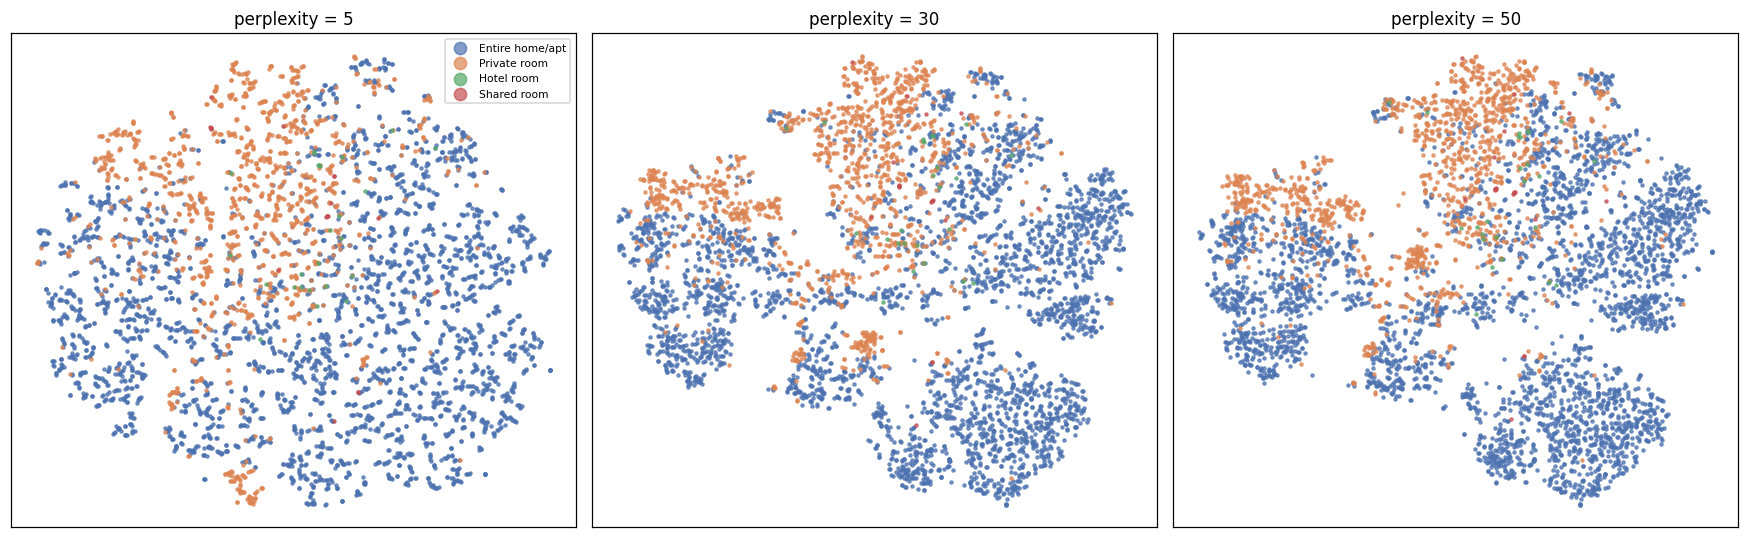

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, perp in zip(axes, [5, 30, 50]):
    Z = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X)
    graficar(Z, tipo, f"perplexity = {perp}", ax, leyenda=(perp == 5))

plt.tight_layout(); plt.show()

## 6.5 — t-SNE es estocástico: el dibujo cambia según dónde arranque

Dos corridas con **exactamente** la misma configuración, Solo cambiamos la semilla

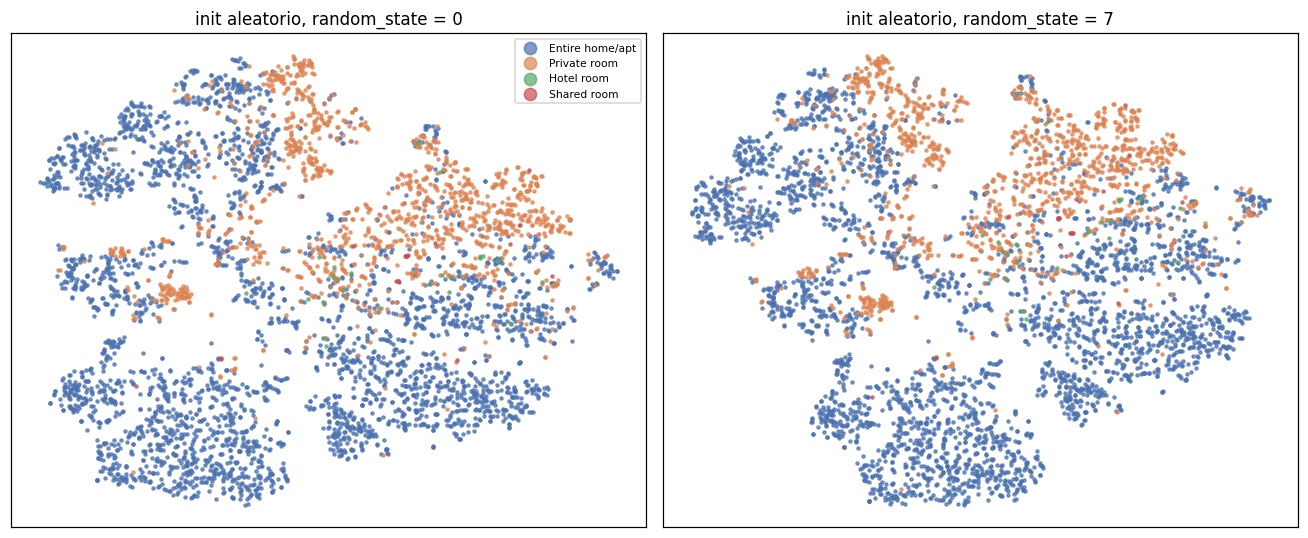

In [54]:


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, semilla in zip(axes, [0, 7]):
    Z = TSNE(
        n_components=2,
        perplexity=30,
        init="random",          # arranque aleatorio -> cada semilla cae en otro mínimo
        learning_rate="auto",   # recomendado por sklearn cuando init="random"
        random_state=semilla,
    ).fit_transform(X)

    graficar(Z, tipo, f"init aleatorio, random_state = {semilla}", ax,
             leyenda=(semilla == 0))

plt.tight_layout()
plt.show()

## 6.6 (Opcional) El mismo gráfico coloreado por distrito

Si el tiempo alcanza. No requiere volver a correr nada: solo cambia la etiqueta de color.

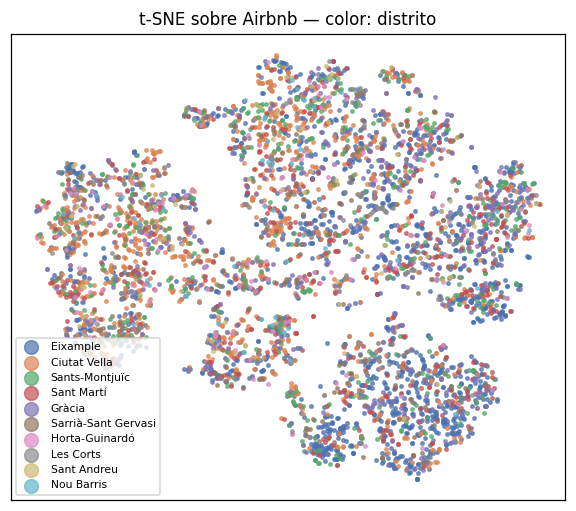

In [55]:
graficar(Z_bien, barrio, "t-SNE sobre Airbnb — color: distrito", s=5)
plt.show()

las variables que le dimos, precio, tamaño y calificaciones, no dependen del barrio

---
# 7. Teoría de UMAP

# UMAP (Uniform Manifold Approximation and Projection)

## ¿Qué es UMAP?
Técnica desarrollada por McInnes y Healy en 2018, está basado en teoría de variedades (manifold learning) y topología algebraica, lo que hace es que construye un grafo ponderado de vecinos en alta dimensión y optimiza un grafo equivalente en baja dimensión.
A diferencia de t-SNE, busca preservar tanto la estructura local como la global.**
#Diferencias con t-SNE:

1.  No modela probabilidades globales, sino la **estructura topológica** del espacio.
2.  No usa una distribución gaussiana fija, sino **conjuntos difusos** basados en la densidad local.

## Diferencias Clave a Primera Vista
| Característica | t-SNE | UMAP |
| :--- | :--- | :--- |
| **Fundamento** | Probabilístico (Divergencia KL) | Topológico / Conjuntos Difusos (Entropía Cruzada) |
| **Estructura** | Preserva vecindarios locales; lo global es aleatorio | Preserva estructura local Y conectividad global |
| **Velocidad** | $O(N^2)$ o $O(N \log N)$ con aproximaciones | Mucho más rápido (grafos dispersos + optimización SGD) |
| **Nuevos datos** | No soporta `.transform()` (solo embedding estático) | Sí soporta proyección de nuevos puntos |
| **Parámetros** | `perplexity` (muy sensible y difícil de ajustar) | `n_neighbors`, `min_dist` (más estables e intuitivos) |
## Grafo de Vecinos Más Cercanos (KNN) y el Rol de $\rho$

## Intuición Geométrica
Antes de calcular distancias complejas, necesitamos definir "quién está cerca de quién". UMAP construye un grafo dirigido donde cada punto se conecta a sus $k$ vecinos más cercanos.

Pero hay un problema crítico: **la densidad de los datos no es uniforme**.
*   En zonas densas, mi vecino más cercano está muy cerca (distancia pequeña).
*   En zonas dispersas, mi vecino más cercano está lejos (distancia grande).

Si usáramos la distancia cruda, los puntos en zonas dispersas parecerían siempre "menos similares" que los de zonas densas, rompiendo la comparación justa.

**La solución ($\rho$):** Para hacer que la medida sea **invariante a la densidad local**, restamos la distancia al vecino más cercano ($\rho_i$). Esto fuerza a que, para cada punto, su vecino más cercano tenga un peso de conexión de exactamente **1.0**. Es como recalibrar la regla de medir para cada punto individualmente según su entorno inmediato.

##Fórmula del Peso Dirigido
El peso de la arista desde el punto $i$ hacia el punto $j$ se define como:

$$w_{ij} = \exp\left(-\frac{\max(0, d(x_i, x_j) - \rho_i)}{\sigma_i}\right)$$

Donde:
*   $d(x_i, x_j)$: Distancia métrica entre los puntos (ej. Euclidiana).
*   $\rho_i$: Distancia al vecino más cercano de $x_i$. Garantiza que el primer vecino tenga peso 1.
*   $\sigma_i$: Parámetro de suavizado ("ancho" de la curva exponencial). Se ajusta mediante búsqueda binaria para lograr una entropía objetivo relacionada con `n_neighbors`.

> **El parámetro `n_neighbors`:** Controla el tamaño efectivo del vecindario local.
> *   Valores bajos (ej. 5-10): Preservan detalles finos y estructura local muy específica.
> *   Valores altos (ej. 50-100): Capturan estructuras globales y conectan clusters más amplios.
>
> Es análogo a la *perplexity* de t-SNE, pero con una interpretación geométrica más directa: es literalmente el número de nodos adyacentes considerados en el grafo inicial.
##  ¿Por qué NO normalizar hace a UMAP tan rápido?

## Intuición Computacional
En t-SNE clásico, se calcula una matriz de afinidades $P$ donde cada fila debe sumar 1 (**normalización explícita**). Esto crea un acoplamiento fuerte: cambiar la posición de un punto afecta la distribución de probabilidad de todos los demás. Además, requiere evaluar la función kernel para muchos pares o mantener estructuras densas durante el cálculo.

UMAP evita esto deliberadamente. Al trabajar con pesos basados en distancias ajustadas por $\rho$ y $\sigma$ **sin forzar la suma a 1**, podemos mantener el grafo como una **matriz dispersa (sparse)**. Solo almacenamos y procesamos las aristas existentes ($k \ll N$).

## Consecuencia en Complejidad
*   **t-SNE:** La normalización acopla todos los puntos. La optimización requiere calcular fuerzas sobre toda la matriz o usar aproximaciones costosas (Barnes-Hut).
*   **UMAP:** Los pesos son independientes por nodo (antes de la simetrización). Esto permite usar **Descenso de Gradiente Estocástico (SGD)** directamente sobre las aristas del grafo.
*   **Resultado:** Pasamos de una complejidad práctica cercana a $O(N^2)$ a una cercana a $O(N \cdot k)$, donde $k$ es pequeño y constante. Esto permite escalar a millones de puntos.
## 4. Entropía Cruzada Binaria vs. Divergencia KL

## Intuición de la Optimización
Aquí reside la diferencia fundamental de comportamiento entre ambos algoritmos:

*   **t-SNE** minimiza la **Divergencia de Kullback-Leibler (KL)**. Es asimétrica: penaliza fuertemente cuando dos puntos están cerca en alta dimensión pero lejos en baja dimensión (falsos negativos), pero es muy indulgente cuando puntos lejanos en alta dimensión aparecen cerca en baja dimensión (falsos positivos). Esto tiende a agrupar todo en bolas compactas, perdiendo la estructura inter-cluster.
*   **UMAP** minimiza la **Entropía Cruzada Binaria**. Trata la presencia/ausencia de cada arista como un problema de clasificación binaria independiente. Penaliza tanto los falsos positivos como los falsos negativos de manera equilibrada.

### Función de Pérdida de UMAP
$$CE = \sum_{e \in E} \left[ \mu_e \log(\nu_e) + (1 - \mu_e) \log(1 - \nu_e) \right]$$

Donde:
*   $\mu_e$: Peso de la arista en el grafo de alta dimensión (datos reales).
*   $\nu_e$: Peso de la arista en el grafo de baja dimensión (embedding actual), calculado usando una curva de Student suavizada.

> **Consecuencia práctica crucial:** El término $(1-\mu_e)\log(1-\nu_e)$ actúa como una **fuerza repulsiva explícita**.
> *   En t-SNE, la repulsión es implícita y débil (solo ocurre porque la suma de probabilidades debe ser 1).
> *   En UMAP, si dos puntos **NO** están conectados en alta dimensión ($\mu \approx 0$), el algoritmo activamente los empuja para que $\nu$ sea cercano a 0 en baja dimensión.
>
> Esto es lo que preserva los espacios vacíos entre clusters y mantiene la estructura global coherente.
## Parámetro `min_dist` y Estabilidad Paramétrica

## Intuición de `min_dist`
Mientras `n_neighbors` controla la escala de la estructura topológica que queremos ver, `min_dist` controla **cuán apretados pueden estar los puntos dentro de un cluster en el embedding final**.

*   **`min_dist = 0.0`**: Los puntos pueden colapsarse unos sobre otros. Maximiza la separación entre clusters distintos, pero pierde la estructura interna de cada grupo.
*   **`min_dist = 0.99`**: Los puntos se distribuyen casi uniformemente dentro del cluster. Se ve la estructura interna detallada, pero los clusters pueden solaparse visualmente.

## Estabilidad vs. Perplexity de t-SNE
La `perplexity` de t-SNE es notoriamente difícil de ajustar porque mezcla el tamaño del vecindario con la varianza del kernel gaussiano y la normalización global. Un cambio pequeño puede alterar drásticamente la visualización completa.

En UMAP, los parámetros son más **ortogonales** (independientes):
1.  `n_neighbors`: Define la escala local/global.
2.  `min_dist`: Define el empaquetamiento geométrico.

Al no haber una normalización global que amplifique errores pequeños, los resultados de UMAP son cualitativamente consistentes en rangos amplios de parámetros (ej. cambiar `n_neighbors` de 15 a 30 suele dar resultados interpretables similares, solo cambiando el nivel de detalle).
## Comparación Honesta: ¿Cuándo SIGUE siendo mejor t-SNE?

A pesar de las ventajas teóricas y prácticas de UMAP, t-SNE no está obsoleto. Como ingenieros de datos, debemos elegir la herramienta adecuada para el objetivo específico:

## Usar t-SNE cuando:
1.  **Visualización pura de clusters muy definidos:** t-SNE tiende a producir separaciones más limpias, compactas y "estéticas". Si tu objetivo es mostrar *"mira cuántos grupos distintos hay"* en una presentación no técnica, t-SNE suele ser más contundente visualmente.
2.  **Datasets pequeños (< 5,000 puntos):** La ventaja computacional de UMAP desaparece. t-SNE exacto puede capturar matices locales muy finos que la aproximación de grafo disperso de UMAP podría suavizar demasiado.
3.  **Validación cruzada de estructuras:** Siempre es buena práctica comparar ambos. Si t-SNE y UMAP muestran estructuras radicalmente diferentes, hay que investigar: puede ser un artefacto de parámetros o una señal real de inestabilidad en los datos.
4.  **Cuando la estructura global NO importa:** Si solo te importan vecindarios ultra-locales y la cohesión interna de clusters pequeños, la agresiva repulsión de UMAP podría separar artificialmente sub-grupos que t-SNE mantendría juntos por su menor presión repulsiva.

### Usar UMAP cuando:
*   Necesitan velocidad en datasets grandes (>50k puntos).
*   Te importa la relación relativa entre clusters (estructura global).
*   Necesitan proyectar nuevos datos en tiempo real o en batch (`.transform()`).
*   Quieren usar el embedding como *features* de entrada para otro modelo downstream (clasificadores, etc.).
*   Buscan reproducibilidad y estabilidad paramétrica en producción.

> **Regla de oro para proyectos:** Empiezar con **UMAP** por defecto debido a su versatilidad y velocidad. Recurrir a **t-SNE** como herramienta de diagnóstico secundario o cuando la estética de clusters compactos y aislados sea el requisito principal de la visualización.

---
# 8. Demo: UMAP sobre Airbnb

Mismos 5.000 anuncios, la misma matriz `X` escalada de la sección 4.
Lo único que cambia es el algoritmo.

⚠️ **Toda esta sección hay que correrla ANTES de exponer.** Son unos 4 minutos de cómputo.

## 8.1 La librería

`umap-learn` no viene con Anaconda ni con scikit-learn: es un paquete aparte.
Se instala como `umap-learn` pero se importa como `umap`.

In [56]:
import umap
import time
print("UMAP listo, versión", umap.__version__)

UMAP listo, versión 0.5.12


## 8.2 El mismo problema, los dos algoritmos

Corremos t-SNE y UMAP uno detrás del otro, con los mismos datos y en la misma máquina,
para que la comparación de tiempos sea justa.


/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWa

t-SNE:   6.4 s
UMAP:    0.9 s
NaN en el resultado de UMAP: 0  (debe ser 0)


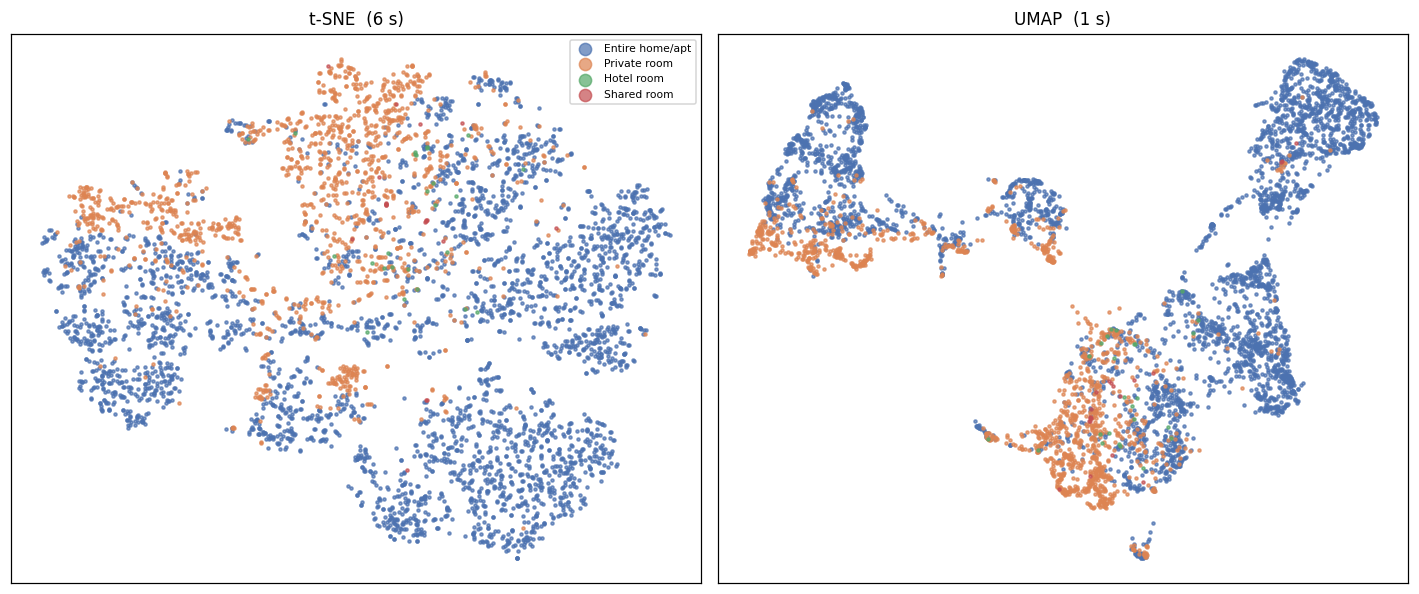

In [57]:
# --- t-SNE ---
t0 = time.time()
Z_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)
t_tsne = time.time() - t0

# --- UMAP, versión rápida (sin semilla -> usa todos los núcleos) ---
t0 = time.time()
umap.UMAP(n_neighbors=15, min_dist=0.1).fit_transform(X)
t_umap = time.time() - t0

# --- UMAP, versión reproducible (con semilla -> el dibujo que mostramos) ---
reductor = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
Z_umap = reductor.fit_transform(X)

print(f"t-SNE: {t_tsne:5.1f} s")
print(f"UMAP:  {t_umap:5.1f} s")
print(f"NaN en el resultado de UMAP: {int(np.isnan(Z_umap).sum())}  (debe ser 0)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
graficar(Z_tsne, tipo, f"t-SNE  ({t_tsne:.0f} s)", axes[0])
graficar(Z_umap, tipo, f"UMAP  ({t_umap:.0f} s)", axes[1], leyenda=False)
plt.tight_layout(); plt.show()

6 veces mas rapido umap en este caso

## 8.3 ¿Separa mejor? La misma medida de antes

Reutilizamos la función `pureza` de la sección 6.3: de los 10 vecinos más cercanos
de cada punto **en el dibujo**, qué proporción es del mismo tipo de alojamiento.

In [58]:
print(f"Si los puntos estuvieran al azar: {azar*100:5.1f}%")
print(f"t-SNE:                            {pureza(Z_tsne, tipo)*100:5.1f}%")
print(f"UMAP:                             {pureza(Z_umap, tipo)*100:5.1f}%")

Si los puntos estuvieran al azar:  60.2%
t-SNE:                             86.1%
UMAP:                              85.1%


los dos algoritmos preservan la vecindad local igual de bien, porque es literalmente lo que los dos optimizan

In [59]:
from scipy.stats import spearmanr

Z_pca = PCA(n_components=2).fit_transform(X)   # referencia: el método lineal

rng = np.random.default_rng(0)
i1 = rng.integers(0, len(X), 3000)
i2 = rng.integers(0, len(X), 3000)

d_alta = np.linalg.norm(X[i1] - X[i2], axis=1)          # distancia real, en 16D

for nombre, Z in [("PCA", Z_pca), ("t-SNE", Z_tsne), ("UMAP", Z_umap)]:
    d_baja = np.linalg.norm(Z[i1] - Z[i2], axis=1)      # distancia en el dibujo
    print(f"{nombre:6s} correlación con la distancia real: {spearmanr(d_alta, d_baja).statistic:.2f}")

PCA    correlación con la distancia real: 0.73
t-SNE  correlación con la distancia real: 0.41
UMAP   correlación con la distancia real: 0.43


/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


## 8.5 Los dos parámetros de UMAP

Arriba cambiamos **`n_neighbors`** (cuántos vecinos mira cada punto al construir el grafo).
Abajo cambiamos **`min_dist`** (qué tan apretados puede dejar los puntos dentro de un grupo).
En cada fila lo demás queda fijo.


/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/teo/Documents

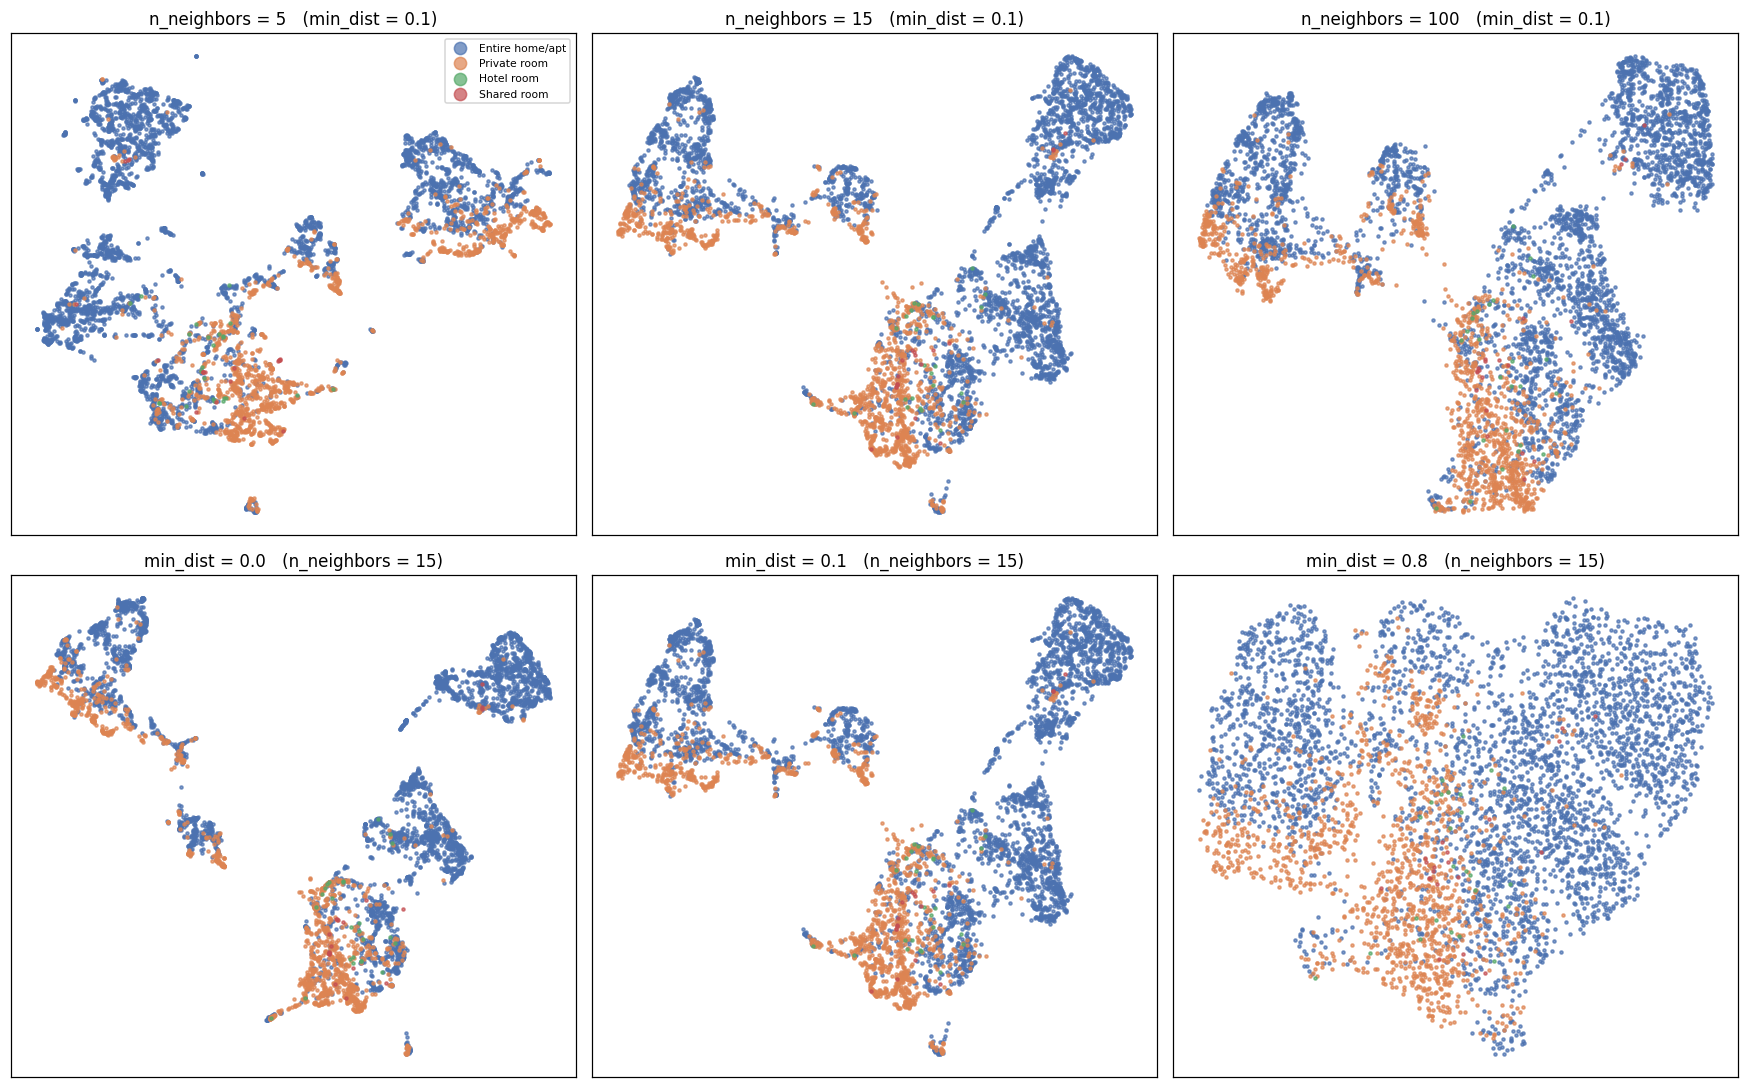

In [60]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Fila 1 - n_neighbors: de mirar muy poquitos vecinos a mirar muchos
for ax, k in zip(axes[0], [5, 15, 100]):
    Z = umap.UMAP(n_neighbors=k, min_dist=0.1, random_state=42).fit_transform(X)
    graficar(Z, tipo, f"n_neighbors = {k}   (min_dist = 0.1)", ax, leyenda=(k == 5))

# Fila 2 - min_dist: de grupos muy compactos a grupos muy esparcidos
for ax, d in zip(axes[1], [0.0, 0.1, 0.8]):
    Z = umap.UMAP(n_neighbors=15, min_dist=d, random_state=42).fit_transform(X)
    graficar(Z, tipo, f"min_dist = {d}   (n_neighbors = 15)", ax, leyenda=False)

plt.tight_layout(); plt.show()

n_neighbors, el equivalente a la perplexity, con 5, el algoritmo solo mira lo inmediato
. Con 100 mira vecindarios grandes y todo se conecta en masas continuas

Abajo muevo min_dist, y este es distinto: no cambia qué estructura encuentra. Los grupos son los mismos. Solo cambió qué tan esparcido se dibujó. Es un parámetro de presentación, no de análisis.

## 8.6 Lo que t-SNE no puede hacer: proyectar anuncios nuevos

UMAP deja un modelo entrenado. Un anuncio que nunca vio se puede ubicar en el
mismo mapa con `.transform()`, sin volver a correr el algoritmo.

LOS 5 ANUNCIOS NUEVOS:
             room_type  accommodates  price  review_scores_rating
5885   Entire home/apt             4  162.0                  4.62
12107  Entire home/apt             6  207.0                  4.71
8837   Entire home/apt             4  291.0                  4.92
6861   Entire home/apt             6  419.0                  4.00
12555     Private room             1   34.0                  5.00


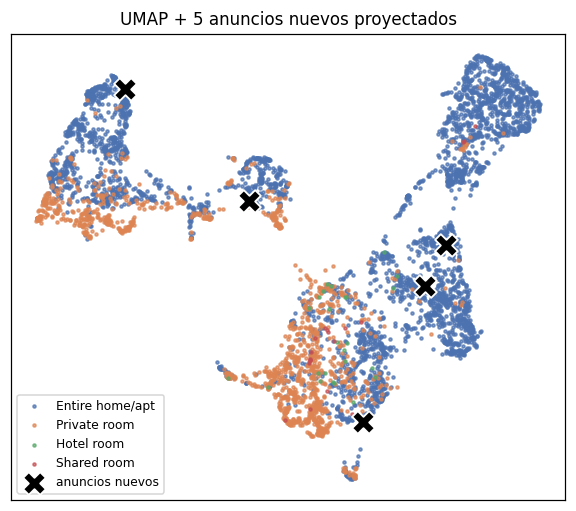

In [61]:
# 5 anuncios que NO estuvieron en la muestra con la que entrenamos UMAP
nuevos = datos.drop(muestra.index).sample(5, random_state=7)

# Se les aplica EXACTAMENTE la misma transformación que a los datos de entrenamiento:
# primero log1p, y luego la media y desviación que el escalador aprendió en 4.5.
# Por eso guardamos 'escalador' en una variable: si creáramos uno nuevo aquí,
# estos 5 anuncios quedarían en otra escala y el mapa no serviría.
X_nuevos = escalador.transform(np.log1p(nuevos[COLS].clip(lower=0)))

# .transform() usa el modelo YA entrenado: no reconstruye el grafo ni reoptimiza nada.
Z_nuevos = reductor.transform(X_nuevos)

print("LOS 5 ANUNCIOS NUEVOS:")
print(nuevos[mostrar].to_string())

ax = graficar(Z_umap, tipo, "UMAP + 5 anuncios nuevos proyectados", s=4)
ax.scatter(Z_nuevos[:, 0], Z_nuevos[:, 1], s=220, marker="X", c="black",
           edgecolor="white", linewidth=1.2, zorder=5, label="anuncios nuevos")
ax.legend(markerscale=1, fontsize=8, loc="best")
plt.show()

## 8.7 Volvemos al mamut

El mismo esqueleto de la sección 3, ahora con los dos algoritmos lado a lado.
Aquí se ve de un vistazo qué significa "preservar la estructura global".

/Users/teo/Documents/Analitica/Expo/.venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP tardó 7 s con los 10000 puntos del mamut


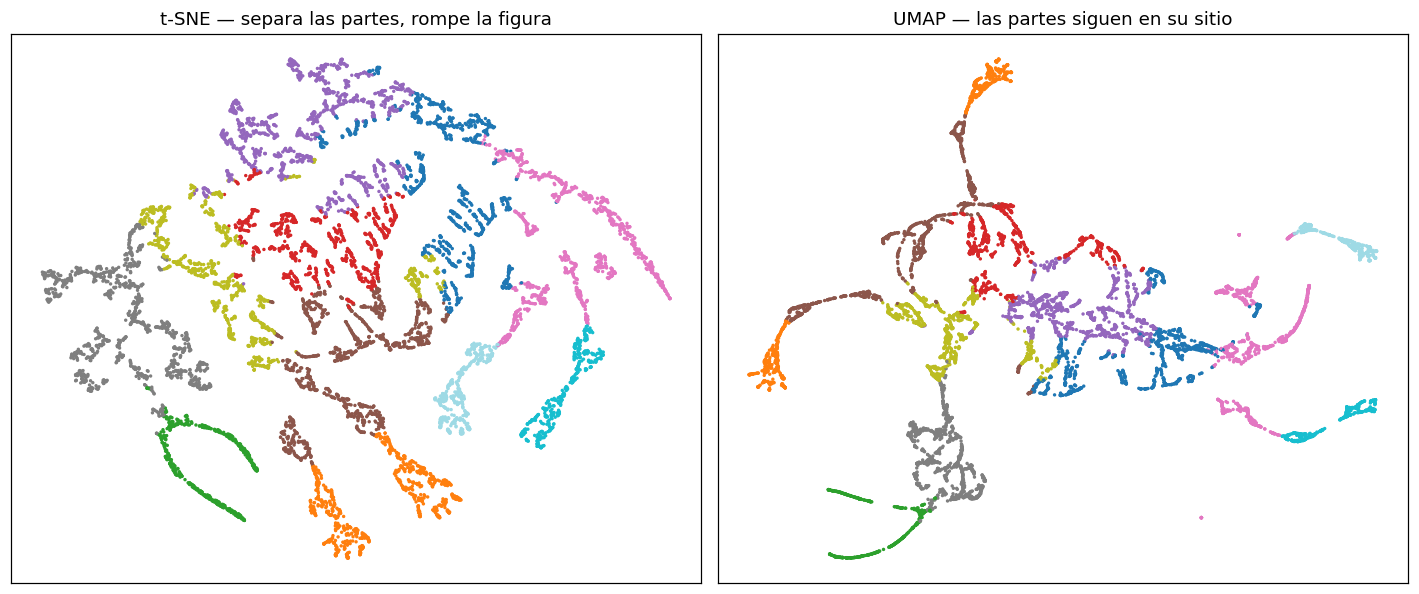

In [62]:
t0 = time.time()
Z_umap_mam = umap.UMAP(n_neighbors=15, min_dist=0.1,
                       random_state=42).fit_transform(X_mam)
print(f"UMAP tardó {time.time()-t0:.0f} s con los {len(X_mam)} puntos del mamut")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(Z_tsne_mam[:, 0], Z_tsne_mam[:, 1], c=y_mam, cmap="tab20", s=1.5)
axes[0].set_title("t-SNE — separa las partes, rompe la figura")
axes[1].scatter(Z_umap_mam[:, 0], Z_umap_mam[:, 1], c=y_mam, cmap="tab20", s=1.5)
axes[1].set_title("UMAP — las partes siguen en su sitio")
for a in axes:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()


Resumiendo la sección: con nuestros datos los dos separan igual de bien, 86 contra 85 de pureza. UMAP fue seis veces más rápido, conserva mejor la estructura global, y es el único que puede ubicar datos nuevos. Con eso paso a las conclusiones.